# Deliverable 2 - Dataset & Pre-Processing


# 0. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, features as F

SEED = 42
np.random.seed(SEED)
np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.max_columns", 50)

# 1. Loading the data

## 1.1 NF-UNSW-NB15-v2

In [ ]:
unsw = data.load_unsw()
print("UNSW shape:", unsw.shape)
unsw.head()

UNSW shape: (2390275, 45)


,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS,DURATION_IN,DURATION_OUT,MIN_TTL,MAX_TTL,LONGEST_FLOW_PKT,SHORTEST_FLOW_PKT,MIN_IP_PKT_LEN,MAX_IP_PKT_LEN,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES,RETRANSMITTED_IN_BYTES,RETRANSMITTED_IN_PKTS,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS,SRC_TO_DST_AVG_THROUGHPUT,DST_TO_SRC_AVG_THROUGHPUT,NUM_PKTS_UP_TO_128_BYTES,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_256_TO_512_BYTES,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label,Attack
0,59.166.0.5,1305.0,149.171.126.8,21.0,6.0,1.0,9.0,1.0,193.0,3.0,24.0,24.0,16.0,0.0,0.0,0.0,31.0,32.0,89.0,52.0,52.0,89.0,456.0,435.0,0.0,0.0,0.0,0.0,3648000.0,3480000.0,15.0,0.0,0.0,0.0,0.0,0.0,7240.0,0.0,0.0,0.0,0.0,0.0,331.0,0,Benign
1,59.166.0.5,1305.0,149.171.126.8,21.0,6.0,1.0,261.0,5.0,469.0,7.0,24.0,24.0,24.0,0.0,0.0,0.0,31.0,32.0,89.0,52.0,52.0,89.0,708.0,711.0,74.0,1.0,89.0,1.0,4656000.0,4584000.0,23.0,0.0,0.0,0.0,0.0,8688.0,8688.0,18944.0,74.0,0.0,0.0,0.0,230.0,0,Benign
2,59.166.0.5,1305.0,149.171.126.8,21.0,6.0,1.0,481.0,9.0,750.0,11.0,24.0,24.0,24.0,0.0,0.0,0.0,31.0,32.0,94.0,52.0,52.0,94.0,928.0,992.0,132.0,2.0,172.0,2.0,5576000.0,5696000.0,31.0,0.0,0.0,0.0,0.0,10136.0,10136.0,33792.0,132.0,0.0,0.0,0.0,229.0,0,Benign
3,59.166.0.5,1305.0,149.171.126.8,21.0,6.0,1.0,701.0,13.0,1054.0,15.0,24.0,24.0,24.0,0.0,0.0,0.0,31.0,32.0,106.0,52.0,52.0,106.0,1148.0,1296.0,190.0,3.0,266.0,3.0,6480000.0,6864000.0,39.0,0.0,0.0,0.0,0.0,11584.0,11584.0,48640.0,190.0,0.0,0.0,0.0,125.0,0,Benign
4,59.166.0.5,1305.0,149.171.126.8,21.0,6.0,1.0,1031.0,19.0,1474.0,21.0,24.0,24.0,24.0,0.0,0.0,0.0,31.0,32.0,106.0,52.0,52.0,106.0,1478.0,1716.0,251.0,4.0,437.0,5.0,7544000.0,8240000.0,51.0,0.0,0.0,0.0,0.0,14480.0,13032.0,64256.0,251.0,0.0,0.0,0.0,230.0,0,Benign


2,390,275 rows and 45 columns (43 features + Label + Attack)

## 1.2 NF-CSE-CIC-IDS2018-v2 (subsample)

The full file has 18.9M rows, too much for our RAM. We read it batch by batch and keep **all attack rows** and **5% of the benign rows**.

In [ ]:
cse = data.load_cse(benign_frac=0.05, seed=SEED)
print("CSE shape (after subsampling):", cse.shape)
cse.head()

CSE shape (after subsampling): (2782621, 43)


,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS,DURATION_IN,DURATION_OUT,MIN_TTL,MAX_TTL,LONGEST_FLOW_PKT,SHORTEST_FLOW_PKT,MIN_IP_PKT_LEN,MAX_IP_PKT_LEN,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES,RETRANSMITTED_IN_BYTES,RETRANSMITTED_IN_PKTS,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS,SRC_TO_DST_AVG_THROUGHPUT,DST_TO_SRC_AVG_THROUGHPUT,NUM_PKTS_UP_TO_128_BYTES,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_256_TO_512_BYTES,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label,Attack
0,40894,22,6,92.0,3164,23,3765,21,27,27,27,0,0,0,63,63,1028,52,52,1028,3164.0,3765.0,0,0,0,0,25312000,30120000,33,7,1,2,1,26883,26847,0,0,0,0,0,0,1,SSH-Bruteforce
1,63269,80,6,7.0,232,5,1136,4,223,222,27,4294827,140,0,127,127,1004,40,40,1004,232.0,1136.0,0,0,0,0,8000,9088000,8,0,0,1,0,8192,26883,0,0,0,0,0,0,1,DDoS attacks-LOIC-HTTP
2,54574,80,6,7.0,522,5,1147,5,219,219,27,4294963,3,3,127,127,975,40,40,975,522.0,1147.0,0,0,0,0,1040000,2288000,8,0,1,1,0,65535,26883,0,0,0,0,0,0,1,DDOS attack-HOIC
3,44500,80,6,7.0,3326,15,160,3,30,26,22,0,0,0,63,63,282,40,40,282,3326.0,160.0,2820,10,0,0,26608000,1280000,7,0,11,0,0,26883,26847,1024,4,0,0,0,0,1,DoS attacks-Slowloris
4,51115,80,6,7.0,647,5,1071,5,27,27,27,0,0,0,128,128,899,40,40,899,647.0,1071.0,0,0,0,0,5176000,8568000,8,0,1,1,0,8192,14600,0,0,0,0,0,0,0,Benign


## 1.3 Check that both files are version 2

In [ ]:
print("UNSW columns:", unsw.shape[1], " CSE columns:", cse.shape[1])
print("Same column names and order:", list(unsw.columns) == list(cse.columns))
print("In UNSW but not in CSE:", set(unsw.columns) - set(cse.columns))
print("In CSE but not in UNSW:", set(cse.columns) - set(unsw.columns))

# the 41 model features (no label, no attack name, no IPs)
features = F.get_feature_columns(unsw)
assert features == F.get_feature_columns(cse), "feature lists differ!"
print("Number of model features:", len(features))

UNSW columns: 45  CSE columns: 43
Same column names and order: False
In UNSW but not in CSE: {'IPV4_SRC_ADDR', 'IPV4_DST_ADDR'}
In CSE but not in UNSW: set()
Number of model features: 41


The CSE file has no IP columns, so its connection key uses ports and protocol only. UNSW uses the full key (IPs, ports, protocol).

# 2. Exploratory Data Analysis

In [ ]:
datasets = {'UNSW': unsw, 'CSE (subsample)': cse}

## 2.1 Class distribution

UNSW {0: 2295222, 1: 95053} -> 4.0% attacks
CSE (subsample) {0: 754591, 1: 2028030} -> 72.9% attacks


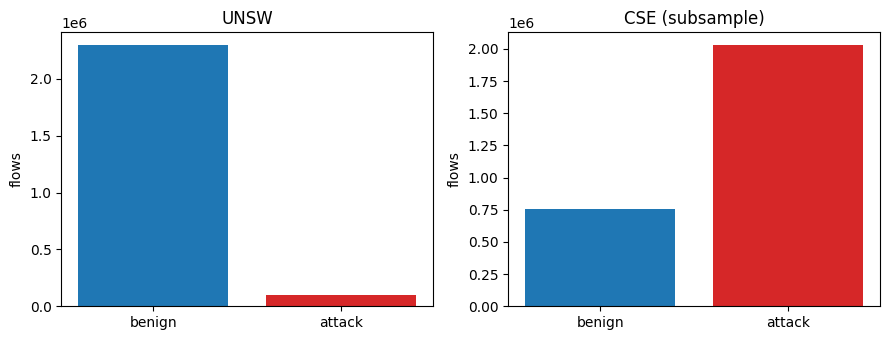

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, (name, df) in zip(axes, datasets.items()):
    counts = df["Label"].value_counts().sort_index()
    ax.bar(["benign", "attack"], counts.values, color=["tab:blue", "tab:red"])
    ax.set_title(name)
    ax.set_ylabel("flows")
    print(name, counts.to_dict(), f"-> {counts[1]/counts.sum():.1%} attacks")
plt.tight_layout()
plt.savefig("results/eda_class_distribution.png", dpi=150)
plt.show()

Attack types in each dataset (names differ, that is why cross-dataset testing is binary only):

In [ ]:
for name, df in datasets.items():
    if "Attack" in df.columns:
        print(name)
        print(df["Attack"].value_counts().to_string(), "\n")

UNSW
Attack
Benign            2295222
Exploits            31551
Fuzzers             22310
Generic             16560
Reconnaissance      12779
DoS                  5794
Analysis             2299
Backdoor             2169
Shellcode            1427
Worms                 164 

CSE (subsample)
Attack
DDOS attack-HOIC            1066881
Benign                       754591
DoS attacks-Hulk             432648
DDoS attacks-LOIC-HTTP       207078
Infilteration                115513
SSH-Bruteforce                94979
Bot                           28033
DoS attacks-GoldenEye         27723
FTP-BruteForce                25933
DoS attacks-SlowHTTPTest      14116
DoS attacks-Slowloris          9512
Brute Force -Web               2143
DDOS attack-LOIC-UDP           2112
Brute Force -XSS                927
SQL Injection                   432 



## 2.2 TTL shortcut

If TTL separates the classes almost perfectly, a model can cheat by learning how the testbed was configured instead of how attacks behave.

In [ ]:
for name, df in datasets.items():
    print(name)
    for label, lname in [(0, "benign"), (1, "attack")]:
        top = df.loc[df["Label"] == label, "MIN_TTL"].value_counts(normalize=True).head(4)
        print(f"  {lname} MIN_TTL top values:", {int(k): f"{v:.1%}" for k, v in top.items()})

UNSW
  benign MIN_TTL top values: {31: '98.4%', 0: '0.5%', 254: '0.5%', 62: '0.3%'}
  attack MIN_TTL top values: {254: '74.7%', 62: '25.1%', 0: '0.2%', 255: '0.0%'}
CSE (subsample)
  benign MIN_TTL top values: {0: '41.6%', 128: '27.4%', 100: '4.5%', 101: '4.2%'}
  attack MIN_TTL top values: {127: '62.8%', 63: '29.8%', 0: '4.1%', 128: '2.8%'}


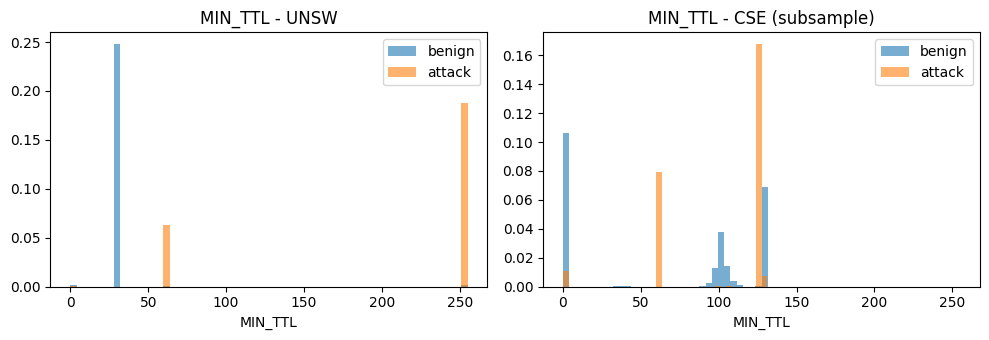

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, df) in zip(axes, datasets.items()):
    ax.hist(df.loc[df["Label"] == 0, "MIN_TTL"], bins=64, alpha=0.6, label="benign", density=True)
    ax.hist(df.loc[df["Label"] == 1, "MIN_TTL"], bins=64, alpha=0.6, label="attack", density=True)
    ax.set_title(f"MIN_TTL - {name}")
    ax.set_xlabel("MIN_TTL")
    ax.legend()
plt.tight_layout()
plt.savefig("results/eda_ttl_histograms.png", dpi=150)
plt.show()

The TTL values are very different between the two networks. In UNSW, benign flows are almost all at 31 and attacks at 254 or 62. In CSE, benign flows are at 0 or 128 and attacks at 127 or 63. A model that learns the UNSW TTL values will fail on CSE, so TTL is kept only in the "all features" set and the ablation will show its effect.

## 2.3 Top destination ports per class

In [ ]:
for name, df in datasets.items():
    print(name)
    for label, lname in [(0, "benign"), (1, "attack")]:
        top = df.loc[df["Label"] == label, "L4_DST_PORT"].value_counts(normalize=True).head(5)
        print(f"  {lname}:", {int(k): f"{v:.1%}" for k, v in top.items()})

UNSW
  benign: {21: '20.4%', 53: '15.6%', 80: '8.3%', 6881: '5.1%', 5190: '5.0%'}
  attack: {80: '18.7%', 0: '14.5%', 53: '12.1%', 21: '10.0%', 111: '9.3%'}
CSE (subsample)
  benign: {53: '49.9%', 3389: '22.1%', 443: '12.8%', 445: '7.7%', 80: '3.4%'}
  attack: {80: '86.3%', 22: '4.7%', 53: '3.4%', 21: '2.0%', 8080: '1.4%'}


## 2.4 Source IPs (why we drop them)

In [ ]:
for name, df in datasets.items():
    if "IPV4_SRC_ADDR" in df.columns:
        print(f"{name}: {df['IPV4_SRC_ADDR'].nunique()} distinct source IPs")
att_ips = unsw.loc[unsw["Label"] == 1, "IPV4_SRC_ADDR"].nunique()
print("UNSW: attacks come from only", att_ips, "distinct source IPs")

UNSW: 40 distinct source IPs
UNSW: attacks come from only 4 distinct source IPs


## 2.5 Correlation heatmap (UNSW, 100k random rows)

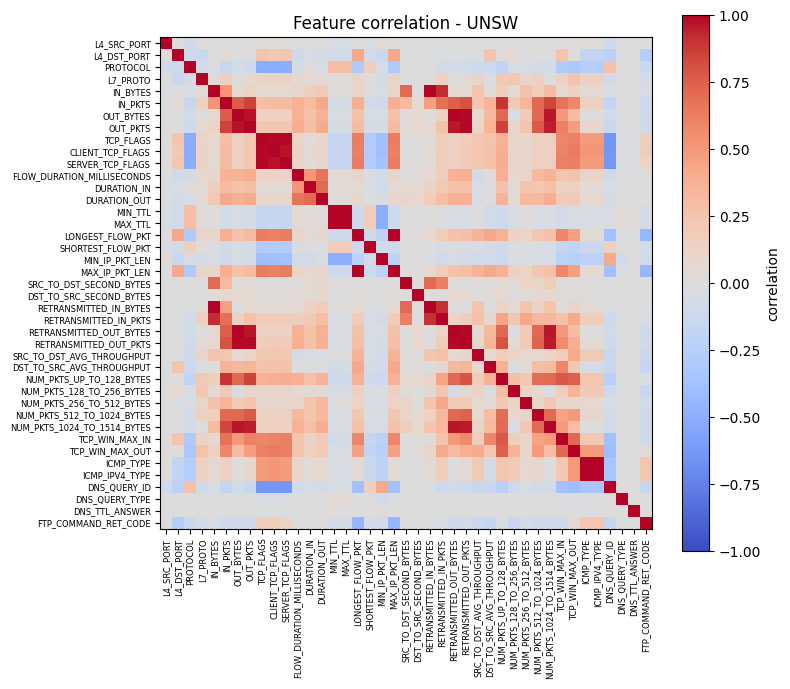

In [ ]:
sample = unsw[features].sample(100_000, random_state=SEED)
corr = sample.corr().fillna(0)

plt.figure(figsize=(8, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="correlation")
plt.xticks(range(len(features)), features, rotation=90, fontsize=6)
plt.yticks(range(len(features)), features, fontsize=6)
plt.title("Feature correlation - UNSW")
plt.tight_layout()
plt.savefig("results/eda_correlation_heatmap.png", dpi=150)
plt.show()

# 3. Cleaning

## 3.1 Connection key

One id per connection (src IP, dst IP, src port, dst port, protocol). The same connection appears in several rows, so we use this id to split the data later and avoid leakage.

In [ ]:
unsw = data.add_connection_key(unsw)
cse = data.add_connection_key(cse)
print("UNSW distinct connections:", unsw["conn_id"].nunique(), "of", len(unsw), "rows")
print("CSE  distinct connections:", cse["conn_id"].nunique(), "of", len(cse), "rows")

UNSW distinct connections: 1906418 of 2390275 rows
CSE  distinct connections: 222477 of 2782621 rows


## 3.2 Duplicates

Rows that are identical on every feature except the IPs and the source port are removed.

In [ ]:
unsw, n_unsw = data.remove_duplicates(unsw)
cse, n_cse = data.remove_duplicates(cse)
print(f"UNSW: removed {n_unsw} rows -> {len(unsw)} left")
print(f"CSE : removed {n_cse} rows -> {len(cse)} left")

UNSW: removed 1529483 rows -> 860792 left
CSE : removed 1734864 rows -> 1047757 left


In [ ]:
for name, df in [("UNSW", unsw), ("CSE", cse)]:
    counts = df["Label"].value_counts().sort_index()
    print(f"{name} after cleaning: benign={counts[0]}, attack={counts[1]} ({counts[1]/len(df):.1%} attacks)")

UNSW after cleaning: benign=821229, attack=39563 (4.6% attacks)
CSE after cleaning: benign=501171, attack=546586 (52.2% attacks)


## 3.3 Final feature lists

IPs are not model inputs. The three feature sets are used later in the ablation:
- `all`: 41 features
- `no_ports`: 39 features
- `no_ports_ttl`: 37 features

In [ ]:
feature_sets = F.make_feature_sets(features)
F.save_feature_sets(feature_sets)
for k, v in feature_sets.items():
    print(k, len(v))

all 41
no_ports 39
no_ports_ttl 37


# 4. Train / Validation / Test split

70% / 15% / 15%, grouped by connection so one connection never appears in two sets. The indices are saved, nobody makes their own split.

In [ ]:
splits = {}
for name, df in [("unsw", unsw), ("cse", cse)]:
    splits[name] = data.split_by_connection(df, seed=SEED)
    tr, va, te = splits[name]
    print(name.upper())
    for sname, idx in [("train", tr), ("val", va), ("test", te)]:
        y = df["Label"].values[idx]
        print(f"  {sname:5s}: {len(idx):8d} rows, {y.mean():.1%} attacks")

    # leakage check: no connection in two sets
    ids = df["conn_id"].values
    assert not set(ids[tr]) & set(ids[va]) and not set(ids[tr]) & set(ids[te])
    print("  no shared connections between sets: OK")

UNSW
  train:   603493 rows, 4.7% attacks
  val  :   128672 rows, 4.4% attacks
  test :   128627 rows, 4.4% attacks
  no shared connections between sets: OK
CSE
  train:   732718 rows, 52.2% attacks
  val  :   159690 rows, 51.9% attacks
  test :   155349 rows, 52.1% attacks
  no shared connections between sets: OK


# 5. Feature transformation

1. `log1p` on the heavy-tailed columns (bytes, packets, durations, throughput)
2. `StandardScaler` fitted on the **train set only**, then applied to validation and test

In [ ]:
import importlib
importlib.reload(data)
processed = {}
for name, df in [("unsw", unsw), ("cse", cse)]:
    tr, va, te = splits[name]
    arrays, scaler = data.transform(df, features, tr, va, te)
    processed[name] = (arrays, scaler)
    print(name.upper(), {k: v.shape for k, v in arrays.items() if k.startswith("X")})

UNSW {'X_train': (603493, 41), 'X_val': (128672, 41), 'X_test': (128627, 41)}
CSE {'X_train': (732718, 41), 'X_val': (159690, 41), 'X_test': (155349, 41)}


In [ ]:
# quick check: train mean ~ 0 and std ~ 1
X = processed["unsw"][0]["X_train"]
print("train mean (max abs):", np.abs(X.mean(axis=0)).max())
print("train std (min, max):", X.std(axis=0).min(), X.std(axis=0).max())

train mean (max abs): 0.0006089155
train std (min, max): 0.99740654 1.0035281


# 6. Saving the processed data

In [ ]:
for name, (arrays, scaler) in processed.items():
    tr, va, te = splits[name]
    data.save_processed(name, arrays, scaler, tr, va, te)
print("Saved in data/processed/ : unsw.npz, cse.npz, scalers, features.json")

Saved in data/processed/ : unsw.npz, cse.npz, scalers, features.json


# 7. Cross-dataset check

For cross- ataset tests the target data is scaled with the **source** scaler, never refitted. We compare the mean of each feature to see how different the two networks look.

In [ ]:
Xs, ys, _, _, Xt, yt = data.load_cross("unsw", "cse")
print("train (UNSW):", Xs.shape, " test (CSE):", Xt.shape)

# features whose mean moves the most between networks
shift = np.abs(Xt.mean(axis=0) - Xs.mean(axis=0))
top = np.argsort(shift)[::-1][:8]
for i in top:
    print(f"{features[i]:32s} shift = {shift[i]:.2f}")

train (UNSW): (603493, 41)  test (CSE): (155349, 41)
DURATION_OUT                     shift = 3.53
DURATION_IN                      shift = 3.49
SRC_TO_DST_AVG_THROUGHPUT        shift = 2.44
TCP_FLAGS                        shift = 2.20
CLIENT_TCP_FLAGS                 shift = 2.19
FLOW_DURATION_MILLISECONDS       shift = 1.97
RETRANSMITTED_OUT_BYTES          shift = 1.38
RETRANSMITTED_OUT_PKTS           shift = 1.35


# 8. First baseline - Random Forest

A quick Random Forest on a 300k subsample of the train set, to have a first result for the deliverable. The full experiments (3 seeds, tuning, all metrics) come in week 2.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

def quick_rf(train_name, test_name, feature_set="all", n_train=300_000):
    if train_name == test_name:
        X_tr, y_tr, _, _, X_te, y_te = data.load_dataset(train_name, feature_set)
    else:
        X_tr, y_tr, _, _, X_te, y_te = data.load_cross(train_name, test_name, feature_set)
    idx = np.random.default_rng(SEED).permutation(len(X_tr))[:n_train]
    rf = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                n_jobs=-1, random_state=SEED)
    rf.fit(X_tr[idx], y_tr[idx])
    pred = rf.predict(X_te)
    return {"train": train_name, "test": test_name, "features": feature_set,
            "precision": precision_score(y_te, pred),
            "recall": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred)}

In [ ]:
rows = []
for tr_name, te_name in [("unsw", "unsw"), ("cse", "cse"), ("cse", "unsw"), ("unsw", "cse")]:
    rows.append(quick_rf(tr_name, te_name))
    print(rows[-1])

baseline = pd.DataFrame(rows).round(3)
baseline.to_csv("results/deliverable2_baseline.csv", index=False)
baseline

{'train': 'unsw', 'test': 'unsw', 'features': 'all', 'precision': 0.9177563661390227, 'recall': 0.9321915414190842, 'F1': 0.9249176348187966}
{'train': 'cse', 'test': 'cse', 'features': 'all', 'precision': 0.9731296826795945, 'recall': 0.8721794302078705, 'F1': 0.9198932430673089}
{'train': 'cse', 'test': 'unsw', 'features': 'all', 'precision': 0.525, 'recall': 0.007340090877315624, 'F1': 0.014477766287487074}
{'train': 'unsw', 'test': 'cse', 'features': 'all', 'precision': 0.15425424753206635, 'recall': 0.028353824124821014, 'F1': 0.04790256821997226}


,train,test,features,precision,recall,F1
0,unsw,unsw,all,0.918,0.932,0.925
1,cse,cse,all,0.973,0.872,0.920
2,cse,unsw,all,0.525,0.007,0.014
3,unsw,cse,all,0.154,0.028,0.048


We expect high scores in dataset and a clear drop in cross dataset. This drop is the main result of the project.

# 9. Summary

In [ ]:
print("Datasets      : NF-UNSW-NB15-v2, NF-CSE-CIC-IDS2018-v2 (subsample)")
print("Model features:", len(features), "(IPs removed)")
print("Cleaning      : connection key, duplicates removed, split by connection")
print("Scaling       : log1p + StandardScaler fitted on train only")
for name in ["unsw", "cse"]:
    tr, va, te = splits[name]
    print(f"{name.upper():5s} train/val/test = {len(tr)} / {len(va)} / {len(te)}")
print("Saved         : data/processed/")

Datasets      : NF-UNSW-NB15-v2, NF-CSE-CIC-IDS2018-v2 (subsample)
Model features: 41 (IPs removed)
Cleaning      : connection key, duplicates removed, split by connection
Scaling       : log1p + StandardScaler fitted on train only
UNSW  train/val/test = 603493 / 128672 / 128627
CSE   train/val/test = 732718 / 159690 / 155349
Saved         : data/processed/
